# Biomedical Temporal KG Drift Experiment - Dynamic Embeddings


In [19]:
import os
import sys
from collections import deque
from dataclasses import dataclass
from pathlib import Path
import hashlib
import json
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.svm import OneClassSVM

PROJECT_DIR = Path(r'D:\biomedical data')
ADAZOR_SRC = PROJECT_DIR / 'adazor' / 'src'
if str(ADAZOR_SRC) not in sys.path:
    sys.path.append(str(ADAZOR_SRC))

try:
    from adazor.detectors import ZTestDriftDetector
except SyntaxError:
    import scipy.stats as st

    class ZTestDriftDetector:
        # Fallback with the same reset/detect interface as adazor.
        def __init__(self, alpha=0.05):
            self.alpha = float(alpha)
            self.is_built = False
            self.tot_orig = 0
            self.n_orig = 0

        def reset(self, outliers):
            outs = np.fromiter((bool(o) for o in outliers), dtype=bool)
            self.tot_orig = int(outs.sum())
            self.n_orig = int(len(outs))
            if self.n_orig == 0:
                raise ValueError('reset requires a non-empty baseline window')
            self.is_built = True

        def detect(self, outliers):
            if not self.is_built:
                raise RuntimeError('ZTestDriftDetector has not been reset.')
            outs = np.fromiter((bool(o) for o in outliers), dtype=bool)
            n = int(len(outs))
            if n == 0:
                return False
            p_outliers = int(outs.sum()) / n
            p_orig = self.tot_orig / self.n_orig
            threshold = st.norm().ppf(1 - self.alpha / 2) / math.sqrt(2 * n)
            return bool(abs(p_outliers - p_orig) > threshold)

        def message(self):
            return 'Z-test Drift Detection (alpha={})'.format(self.alpha)

RESULTS_DIR = PROJECT_DIR / 'biomedical_experiment_results'
RESULTS_DIR.mkdir(exist_ok=True)
PYSTOW_HOME = PROJECT_DIR / '.pystow'
PYSTOW_HOME.mkdir(exist_ok=True)
os.environ.setdefault('PYSTOW_HOME', str(PYSTOW_HOME))

TEMPORAL_TRIPLES_PATH = PROJECT_DIR / 'drifting_edges_timestamp.csv'
if not TEMPORAL_TRIPLES_PATH.exists():
    TEMPORAL_TRIPLES_PATH = PROJECT_DIR / 'drifting_edges_timestamp.tsv'

INITIAL_CUTOFF_YEAR = 2010
TARGET_TYPE = 'Gene - causes_or_contributes_to_condition - Disease'
EMBEDDING_DIM = 32
EMBEDDING_RANDOM_STATE = 42
EMBEDDING_EPOCHS = 2
EMBEDDING_BATCH_SIZE = 2048
WINDOW_SIZE = 250
NU = 0.1
GAMMA = 0.5
ALPHA = 0.025
STANDARDIZE = False
KEEP_FRACTION_AFTER_DRIFT = 0.10
EMBEDDING_SHIFT_RETRAIN_THRESHOLD = 0.15

print('Project:', PROJECT_DIR)
print('Temporal triples:', TEMPORAL_TRIPLES_PATH)
print('PyStow home:', PYSTOW_HOME)
print('Target type:', TARGET_TYPE)


Project: D:\biomedical data
Temporal triples: D:\biomedical data\drifting_edges_timestamp.tsv
PyStow home: D:\biomedical data\.pystow
Target type: Gene - causes_or_contributes_to_condition - Disease


In [20]:
def read_table_auto(path, usecols=None, nrows=None, chunksize=None):
    # Read CSV/TSV inputs without loading generated embedding outputs.
    sep = '\t' if path.suffix.lower() == '.tsv' else ','
    return pd.read_csv(path, sep=sep, usecols=usecols, nrows=nrows, chunksize=chunksize)


def infer_event_year(df):
    # Prefer explicit year, otherwise derive a year from timestamp text.
    if 'year' in df.columns:
        year = pd.to_numeric(df['year'], errors='coerce')
    else:
        year = pd.Series(np.nan, index=df.index, dtype='float64')
    timestamp_year = pd.to_numeric(df['timestamp'].astype(str).str.extract(r'(\d{4})', expand=False), errors='coerce')
    return year.fillna(timestamp_year)


def sort_temporal_triples(df):
    # Sort static rows first, then future rows by event time and row order.
    numeric_ts = pd.to_numeric(df['timestamp'].where(df['timestamp'].ne(''), '0'), errors='coerce').fillna(0)
    sorted_df = df.assign(_missing_ts=df['timestamp'].eq(''), _numeric_ts=numeric_ts).sort_values(
        by=['_missing_ts', 'event_year', '_numeric_ts', 'row_number'],
        ascending=[False, True, True, True],
        kind='stable',
    )
    sorted_df = sorted_df.drop(columns=['_missing_ts', '_numeric_ts']).reset_index(drop=True)
    sorted_df['stream_position'] = np.arange(1, len(sorted_df) + 1)
    return sorted_df


def load_temporal_triples(path):
    # Load only temporal KG triples; embeddings are generated later from KG state.
    required_cols = ['subject', 'object', 'edge_type', 'timestamp']
    sample = read_table_auto(path, nrows=0)
    optional_cols = [c for c in ['year', 'month', 'day', 'type'] if c in sample.columns]
    df = read_table_auto(path, usecols=required_cols + optional_cols)
    df['row_number'] = np.arange(1, len(df) + 1)
    df['timestamp'] = df['timestamp'].fillna('').astype(str)
    if 'type' not in df.columns:
        df['type'] = df['subject'].map(lambda _: '')
    df['event_year'] = infer_event_year(df)
    return sort_temporal_triples(df)


def build_initial_knowledge_graph(triples_df, cutoff_year=INITIAL_CUTOFF_YEAR, target_type=None):
    # Initial KG uses only triples known through the cutoff year.
    initial_mask = triples_df['event_year'].isna() | (triples_df['event_year'] <= cutoff_year)
    initial_kg = triples_df.loc[initial_mask].copy().reset_index(drop=True)
    future_df = triples_df.loc[~initial_mask].copy().reset_index(drop=True)
    if target_type is None:
        initial_stream = initial_kg.copy().reset_index(drop=True)
        future_stream = future_df.copy().reset_index(drop=True)
    else:
        initial_stream = initial_kg[initial_kg['type'].eq(target_type)].copy().reset_index(drop=True)
        future_stream = future_df[future_df['type'].eq(target_type)].copy().reset_index(drop=True)
    lookup = build_lookup_sets(initial_kg)
    return initial_kg, initial_stream, future_stream, lookup


def build_lookup_sets(kg_df):
    # Store elements known in the current KG state.
    return {
        'nodes': set(kg_df['subject']).union(set(kg_df['object'])),
        'edge_types': set(kg_df['edge_type']),
    }


def triple_has_unseen_elements(row, lookup):
    # Check before adding the row to the KG.
    return (
        row['subject'] not in lookup['nodes']
        or row['object'] not in lookup['nodes']
        or row['edge_type'] not in lookup['edge_types']
    )


def update_knowledge_graph(kg_df, rows, lookup):
    # Add every incoming temporal triple to the current KG.
    rows_df = pd.DataFrame(rows) if not isinstance(rows, pd.DataFrame) else rows.copy()
    if rows_df.empty:
        return kg_df, lookup
    keep_cols = [c for c in kg_df.columns if c in rows_df.columns]
    rows_df = rows_df[keep_cols].copy()
    kg_df = pd.concat([kg_df, rows_df], ignore_index=True)
    lookup['nodes'].update(rows_df['subject'])
    lookup['nodes'].update(rows_df['object'])
    lookup['edge_types'].update(rows_df['edge_type'])
    return kg_df, lookup


In [21]:
@dataclass
class EmbeddingState:
    node_embeddings: dict
    edge_type_embeddings: dict
    node_dim: int
    edge_dim: int
    kg_rows: int


def normalize_vector(vec):
    vec = np.asarray(vec, dtype=np.float64)
    norm = np.linalg.norm(vec)
    if norm == 0:
        return vec
    return vec / norm


def _compute_predicate_embeddings_from_transe_translation(kg_df, node_embeddings, embedding_size):
    predicate_vectors = {}
    grouped = kg_df[['subject', 'edge_type', 'object']].dropna().groupby('edge_type', sort=True)
    for predicate, rows in grouped:
        diffs = []
        for row in rows.itertuples(index=False):
            subject_vec = node_embeddings.get(str(row.subject))
            object_vec = node_embeddings.get(str(row.object))
            if subject_vec is not None and object_vec is not None:
                diffs.append(object_vec - subject_vec)
        if diffs:
            predicate_vectors[str(predicate)] = normalize_vector(np.mean(diffs, axis=0))
        else:
            predicate_vectors[str(predicate)] = np.zeros(embedding_size, dtype=np.float64)
    return predicate_vectors


def _extract_pykeen_embeddings(model, labels):
    representation = model
    if not hasattr(representation, '_embeddings') and hasattr(representation, '__getitem__'):
        representation = representation[0]
    if not hasattr(representation, '_embeddings'):
        raise AttributeError('PyKEEN representation does not expose an embedding weight matrix.')
    weights = representation._embeddings.weight.detach().cpu().numpy()
    return {str(label): normalize_vector(weights[i]) for i, label in enumerate(labels)}


def generate_transe_embeddings_from_kg(kg_df, embedding_size=32, random_state=42):
    # Generate TransE embeddings only from the KG known at the current time.
    try:
        from pykeen.models import TransE
        from pykeen.training import SLCWATrainingLoop
        from pykeen.triples import TriplesFactory
    except Exception as exc:
        raise RuntimeError(
            'PyKEEN TransE embeddings are unavailable in this environment. '
            'Install compatible pykeen dependencies and ensure PYSTOW_HOME is writable.'
        ) from exc

    if kg_df.empty:
        raise ValueError('Cannot generate embeddings from an empty KG.')

    #nodes = pd.Index(pd.concat([kg_df['subject'], kg_df['object']], ignore_index=True).dropna().astype(str).unique())
    #nodes_df = pd.DataFrame({'name': sorted(nodes.tolist()), 'type': 'unknown'})
    edges_df = kg_df[['subject', 'edge_type', 'object']].dropna().copy()
    edges_df = edges_df.rename(columns={'edge_type': 'predicate'})
    edges_df[['subject', 'predicate', 'object']] = edges_df[['subject', 'predicate', 'object']].astype(str)
    triples = edges_df[['subject', 'predicate', 'object']].to_numpy(dtype=str)
    triples_factory = TriplesFactory.from_labeled_triples(triples)

    model = TransE(
        triples_factory=triples_factory,
        embedding_dim=embedding_size,
        random_seed=random_state,
    )
    training_loop = SLCWATrainingLoop(model=model, triples_factory=triples_factory)
    training_loop.train(
        triples_factory=triples_factory,
        num_epochs=EMBEDDING_EPOCHS,
        batch_size=min(EMBEDDING_BATCH_SIZE, max(32, len(triples))),
        use_tqdm=False,
        use_tqdm_batch=False,
        pin_memory=False,
        num_workers=0,
    )

    node_labels = list(triples_factory.entity_to_id.keys())
    relation_labels = list(triples_factory.relation_to_id.keys())
    node_embeddings = _extract_pykeen_embeddings(model.entity_representations, node_labels)
    try:
        edge_type_embeddings = _extract_pykeen_embeddings(model.relation_representations, relation_labels)
    except Exception:
        edge_type_embeddings = _compute_predicate_embeddings_from_transe_translation(
            edges_df.rename(columns={'predicate': 'edge_type'}),
            node_embeddings,
            embedding_size,
        )

    node_embeddings = {node: np.asarray(vec, dtype=np.float64) for node, vec in node_embeddings.items()}
    edge_type_embeddings = {edge_type: normalize_vector(vec) for edge_type, vec in edge_type_embeddings.items()}
    return EmbeddingState(
        node_embeddings=node_embeddings,
        edge_type_embeddings=edge_type_embeddings,
        node_dim=embedding_size,
        edge_dim=embedding_size,
        kg_rows=int(len(kg_df)),
    )


In [ ]:

def create_hadamard_features(row, embedding_state):
    # Compose with embeddings valid for the current KG time.
    s = embedding_state.node_embeddings[row['subject']]
    p = embedding_state.edge_type_embeddings[row['edge_type']]
    o = embedding_state.node_embeddings[row['object']]
    return s * p * o


def create_concatenation_features(row, embedding_state):
    # Concatenate subject, predicate, and object embeddings.
    s = embedding_state.node_embeddings[row['subject']]
    p = embedding_state.edge_type_embeddings[row['edge_type']]
    o = embedding_state.node_embeddings[row['object']]
    return np.concatenate([s, p, o])


def feature_columns(dim):
    return [f'f{i}' for i in range(dim)]


def row_to_feature_record(row, embedding_state, compose_fn, feature_cols):
    # Convert one raw triple row into one embedded feature record.
    features = compose_fn(row, embedding_state)
    record = {col: row[col] for col in row.index if col not in ['year', 'month', 'day']}
    for col, value in zip(feature_cols, features):
        record[col] = float(value)
    return record


def rows_to_feature_frame(rows_df, embedding_state, compose_fn, feature_cols):
    # Rebuild feature vectors from raw triples whenever embeddings refresh.
    records = [row_to_feature_record(row, embedding_state, compose_fn, feature_cols) for _, row in rows_df.iterrows()]
    return pd.DataFrame(records)


def build_feature_matrix(df, feature_cols, scaler=None, fit=False):
    X = df.loc[:, feature_cols].to_numpy(dtype=np.float64)
    if scaler is None:
        return X, None
    if fit:
        return scaler.fit_transform(X), scaler
    return scaler.transform(X), scaler


def outlier_flags_from_ocsvm(ocsvm, X):
    # OCSVM predicts -1 for outliers.
    return ocsvm.predict(X) == -1


def train_classifier(reference_features_df, feature_cols, nu=NU, gamma=GAMMA, standardize=STANDARDIZE):
    # Train OCSVM on the current reference feature window.
    scaler = StandardScaler() if standardize else None
    X_ref, scaler = build_feature_matrix(reference_features_df, feature_cols, scaler=scaler, fit=True)
    ocsvm = OneClassSVM(kernel='rbf', nu=nu, gamma=gamma)
    ocsvm.fit(X_ref)
    flags = outlier_flags_from_ocsvm(ocsvm, X_ref)
    labeled = reference_features_df.copy()
    labeled['ocsvm_prediction'] = np.where(flags, -1, 1)
    labeled['ocsvm_label'] = np.where(flags, 'outlier', 'normal')
    labeled['outlier_flag'] = flags.astype(int)
    return labeled, ocsvm, scaler, flags


def retrain_reference_model(current_reference_raw_df, current_embedding_state, compose_fn, feature_cols, detector, nu=NU, gamma=GAMMA, standardize=STANDARDIZE):
    # Refresh the OCSVM reference using the current raw reference rows and embeddings.
    reference_features = rows_to_feature_frame(current_reference_raw_df, current_embedding_state, compose_fn, feature_cols)
    _, new_ocsvm, new_scaler, new_reference_flags = train_classifier(
        reference_features,
        feature_cols,
        nu=nu,
        gamma=gamma,
        standardize=standardize,
    )
    detector.reset(new_reference_flags)
    return reference_features, new_ocsvm, new_scaler, new_reference_flags


def build_labeled_window_snapshot(window_features_df, outlier_flags, drift_event_id, drift_stream_position):
    # Store the feature window that triggered drift and its labels.
    snapshot = window_features_df.copy().reset_index(drop=True)
    snapshot['ocsvm_prediction'] = np.where(outlier_flags, -1, 1)
    snapshot['ocsvm_label'] = np.where(outlier_flags, 'outlier', 'normal')
    snapshot['outlier_flag'] = np.asarray(outlier_flags, dtype=int)
    snapshot['drift_event_id'] = int(drift_event_id)
    snapshot['drift_stream_position'] = int(drift_stream_position)
    return snapshot


def _shared_embedding_delta_vectors(old_embeddings, new_embeddings):
    # Compare only elements that exist in both embedding states.
    shared_keys = sorted(set(old_embeddings).intersection(new_embeddings))
    if not shared_keys:
        return shared_keys, np.empty((0, 0), dtype=np.float64), np.empty((0,), dtype=np.float64)
    deltas = np.vstack([
        np.asarray(new_embeddings[key], dtype=np.float64) - np.asarray(old_embeddings[key], dtype=np.float64)
        for key in shared_keys
    ])
    distances = np.linalg.norm(deltas, axis=1)
    return shared_keys, deltas, distances


def build_embedding_shift_record(old_state, new_state, row, composition_name, iteration, trigger_reason, is_drift, threshold):
    # Summarize how much shared element embeddings moved after regeneration.
    shared_nodes, node_deltas, node_distances = _shared_embedding_delta_vectors(
        old_state.node_embeddings,
        new_state.node_embeddings,
    )
    shared_edge_types, edge_deltas, edge_distances = _shared_embedding_delta_vectors(
        old_state.edge_type_embeddings,
        new_state.edge_type_embeddings,
    )

    delta_parts = [part for part in [node_deltas, edge_deltas] if part.size]
    distance_parts = [part for part in [node_distances, edge_distances] if part.size]
    if delta_parts:
        all_deltas = np.vstack(delta_parts)
        all_distances = np.concatenate(distance_parts)
        avg_distance = float(np.mean(all_distances))
        bounding_box_width = float(np.linalg.norm(all_deltas.max(axis=0) - all_deltas.min(axis=0)))
        mad = float(np.mean(np.abs(all_distances - avg_distance)))
    else:
        avg_distance = np.nan
        bounding_box_width = np.nan
        mad = np.nan

    threshold_exceeded = bool(np.isfinite(avg_distance) and avg_distance > threshold)
    return {
        'iteration': int(iteration),
        'stream_position': int(row['stream_position']),
        'row_number': int(row['row_number']),
        'timestamp': row['timestamp'],
        'type': row['type'],
        'subject': row['subject'],
        'edge_type': row['edge_type'],
        'object': row['object'],
        'composition': composition_name,
        'trigger_reason': trigger_reason,
        'is_drift': bool(is_drift),
        'avg_euclidean_distance': avg_distance,
        'bounding_box_width': bounding_box_width,
        'mad': mad,
        'shared_nodes': int(len(shared_nodes)),
        'shared_edge_types': int(len(shared_edge_types)),
        'compared_elements': int(len(shared_nodes) + len(shared_edge_types)),
        'distance_threshold': float(threshold),
        'threshold_exceeded': bool(threshold_exceeded),
        'retrained_ocsvm': bool(is_drift),
        'embedding_kg_rows': int(new_state.kg_rows),
    }


def build_avg_distance_trace(shift_df):
    # Keep a compact trace for plotting mean embedding movement over time.
    if shift_df.empty:
        return pd.DataFrame(columns=['iteration', 'avg_euclidean_distance', 'is_drift', 'trigger_reason', 'composition'])
    cols = ['iteration', 'avg_euclidean_distance', 'is_drift', 'trigger_reason', 'composition']
    return shift_df.loc[:, cols].copy()


def save_avg_distance_plot(trace_df, output_path, title):
    # Plot average embedding movement over algorithm iterations.
    fig, ax = plt.subplots(figsize=(10, 4.5))
    if trace_df.empty:
        ax.set_title(title)
        ax.set_xlabel('Iteration')
        ax.set_ylabel('Average Euclidean Distance')
        ax.text(0.5, 0.5, 'No embedding refresh events', ha='center', va='center', transform=ax.transAxes)
    else:
        ordered = trace_df.sort_values('iteration').reset_index(drop=True)
        ax.step(ordered['iteration'], ordered['avg_euclidean_distance'], where='post', color='steelblue', linewidth=1.5)
        non_drift = ordered[~ordered['is_drift']]
        drift = ordered[ordered['is_drift']]
        if not non_drift.empty:
            ax.scatter(non_drift['iteration'], non_drift['avg_euclidean_distance'], color='blue', s=18, label='Non-drift refresh')
        if not drift.empty:
            ax.scatter(drift['iteration'], drift['avg_euclidean_distance'], color='red', s=30, label='Drift-triggered refresh')
        ax.legend(loc='best')
        ax.set_title(title)
        ax.set_xlabel('Iteration')
        ax.set_ylabel('Average Euclidean Distance')
    fig.tight_layout()
    fig.savefig(output_path, dpi=160)
    plt.close(fig)


In [23]:

def process_triple_for_features(row, kg_df, lookup, embedding_state, compose_fn, feature_cols, composition_name, iteration, retrain_threshold):
    # Add the new triple, then refresh TransE embeddings only if a new element appeared.
    has_unseen = triple_has_unseen_elements(row, lookup)
    kg_df, lookup = update_knowledge_graph(kg_df, pd.DataFrame([row]), lookup)
    shift_record = None
    if has_unseen:
        old_state = embedding_state
        embedding_state = generate_transe_embeddings_from_kg(kg_df, embedding_size=EMBEDDING_DIM, random_state=EMBEDDING_RANDOM_STATE)
        shift_record = build_embedding_shift_record(
            old_state,
            embedding_state,
            row,
            composition_name,
            iteration,
            trigger_reason='unseen_element',
            is_drift=False,
            threshold=retrain_threshold,
        )
    record = row_to_feature_record(row, embedding_state, compose_fn, feature_cols)
    return record, kg_df, lookup, embedding_state, shift_record


def rebuild_reference_after_drift(reference_raw_df, kg_df, lookup, embedding_state, compose_fn, feature_cols, composition_name, iteration, drift_row, retrain_threshold):
    # After drift, regenerate TransE embeddings from current KG and rebuild reference features.
    old_state = embedding_state
    embedding_state = generate_transe_embeddings_from_kg(kg_df, embedding_size=EMBEDDING_DIM, random_state=EMBEDDING_RANDOM_STATE)
    shift_record = build_embedding_shift_record(
        old_state,
        embedding_state,
        drift_row,
        composition_name,
        iteration,
        trigger_reason='drift',
        is_drift=True,
        threshold=retrain_threshold,
    )
    reference_features_df = rows_to_feature_frame(reference_raw_df, embedding_state, compose_fn, feature_cols)
    return reference_features_df, kg_df, lookup, embedding_state, shift_record


def detect_drift(detector, current_flags):
    # Preserve the existing Z-test drift detector behavior.
    return detector.detect(current_flags)


def run_dynamic_ocsvm_ztest_stream_keep10(
    initial_kg,
    initial_stream,
    future_stream,
    lookup,
    compose_fn,
    feature_cols,
    composition_name,
    window_size=WINDOW_SIZE,
    nu=NU,
    gamma=GAMMA,
    alpha=ALPHA,
    standardize=STANDARDIZE,
    keep_fraction_after_drift=KEEP_FRACTION_AFTER_DRIFT,
    embedding_shift_retrain_threshold=EMBEDDING_SHIFT_RETRAIN_THRESHOLD,
):
    # Initial embeddings are generated only from KG known through the threshold year.
    if initial_stream.empty:
        raise ValueError(f'No initial training triples for {composition_name}.')
    if future_stream.empty:
        raise ValueError(f'No future stream triples for {composition_name}.')

    kg_df = initial_kg.copy().reset_index(drop=True)
    lookup = {'nodes': set(lookup['nodes']), 'edge_types': set(lookup['edge_types'])}
    embedding_state = generate_transe_embeddings_from_kg(kg_df, embedding_size=EMBEDDING_DIM, random_state=EMBEDDING_RANDOM_STATE)

    if len(initial_stream) < 2:
        raise ValueError(f'Need at least 2 initial triples for {composition_name} to separate training and monitoring windows.')

    seed_window_size = min(window_size, len(initial_stream) - 1)
    reference_raw_df = initial_stream.iloc[:-seed_window_size].copy().reset_index(drop=True)
    initial_window_raw_df = initial_stream.iloc[-seed_window_size:].copy().reset_index(drop=True)
    initial_features_df = rows_to_feature_frame(reference_raw_df, embedding_state, compose_fn, feature_cols)
    labeled_initial_reference, ocsvm, scaler, reference_flags = train_classifier(
        initial_features_df,
        feature_cols=feature_cols,
        nu=nu,
        gamma=gamma,
        standardize=standardize,
    )

    detector = ZTestDriftDetector(alpha=alpha)
    detector.reset(reference_flags)

    current_raw_window = deque(
        initial_window_raw_df.to_dict('records'),
        maxlen=window_size,
    )
    future_records = future_stream.to_dict('records')

    embedding_shift_records = []
    threshold_retrain_count = 0
    i = 0
    iteration = 0
    step_records = []

    while len(current_raw_window) < window_size and i < len(future_records):
        row = pd.Series(future_records[i])
        i += 1
        iteration += 1
        warmup_record, kg_df, lookup, embedding_state, shift_record = process_triple_for_features(
            row, kg_df, lookup, embedding_state, compose_fn, feature_cols, composition_name, iteration, embedding_shift_retrain_threshold
        )
        if shift_record is not None and shift_record['threshold_exceeded']:
            _, ocsvm, scaler, reference_flags = retrain_reference_model(
                reference_raw_df,
                embedding_state,
                compose_fn,
                feature_cols,
                detector,
                nu=nu,
                gamma=gamma,
                standardize=standardize,
            )
            shift_record['retrained_ocsvm'] = True
            threshold_retrain_count += 1
        if shift_record is not None:
            embedding_shift_records.append(shift_record)
        current_raw_window.append(row.to_dict())
        step_records.append({
            'iteration': int(iteration),
            'stream_position': int(warmup_record['stream_position']),
            'row_number': int(warmup_record['row_number']),
            'timestamp': warmup_record['timestamp'],
            'type': warmup_record['type'],
            'subject': warmup_record['subject'],
            'edge_type': warmup_record['edge_type'],
            'object': warmup_record['object'],
            'composition': composition_name,
            'drift_tested': False,
            'drift_detected': False,
            'reference_outlier_fraction': np.nan,
            'current_outlier_fraction': np.nan,
            'embedding_kg_rows': int(embedding_state.kg_rows),
        })

    first_drift_detected = False
    drift_records = []
    drift_windows = []
    window_history = []

    while i < len(future_records):
        row = pd.Series(future_records[i])
        i += 1
        iteration += 1
        feature_record, kg_df, lookup, embedding_state, shift_record = process_triple_for_features(
            row, kg_df, lookup, embedding_state, compose_fn, feature_cols, composition_name, iteration, embedding_shift_retrain_threshold
        )
        if shift_record is not None and shift_record['threshold_exceeded']:
            _, ocsvm, scaler, reference_flags = retrain_reference_model(
                reference_raw_df,
                embedding_state,
                compose_fn,
                feature_cols,
                detector,
                nu=nu,
                gamma=gamma,
                standardize=standardize,
            )
            shift_record['retrained_ocsvm'] = True
            threshold_retrain_count += 1
        if shift_record is not None:
            embedding_shift_records.append(shift_record)
        current_raw_window.append(row.to_dict())

        current_raw_df = pd.DataFrame(list(current_raw_window)).reset_index(drop=True)
        current_features_df = rows_to_feature_frame(current_raw_df, embedding_state, compose_fn, feature_cols)
        X_curr, _ = build_feature_matrix(current_features_df, feature_cols, scaler=scaler, fit=False)
        current_flags = outlier_flags_from_ocsvm(ocsvm, X_curr)
        is_drift = detect_drift(detector, current_flags)

        stream_position = int(feature_record['stream_position'])
        row_number = int(feature_record['row_number'])
        timestamp_value = feature_record['timestamp']
        type_value = feature_record['type']
        current_outlier_fraction = float(np.mean(current_flags)) if len(current_flags) else 0.0
        reference_outlier_fraction = float(reference_flags.mean()) if len(reference_flags) else 0.0

        window_history.append({
            'iteration': int(iteration),
            'stream_position': stream_position,
            'row_number': row_number,
            'timestamp': timestamp_value,
            'type': type_value,
            'composition': composition_name,
            'window_size': int(len(current_features_df)),
            'reference_size': int(len(reference_flags)),
            'reference_outlier_fraction': reference_outlier_fraction,
            'current_outlier_fraction': current_outlier_fraction,
            'drift_detected': bool(is_drift),
            'embedding_kg_rows': int(embedding_state.kg_rows),
        })
        step_records.append({
            'iteration': int(iteration),
            'stream_position': stream_position,
            'row_number': row_number,
            'timestamp': timestamp_value,
            'type': type_value,
            'subject': feature_record['subject'],
            'edge_type': feature_record['edge_type'],
            'object': feature_record['object'],
            'composition': composition_name,
            'drift_tested': True,
            'drift_detected': bool(is_drift),
            'reference_outlier_fraction': reference_outlier_fraction,
            'current_outlier_fraction': current_outlier_fraction,
            'embedding_kg_rows': int(embedding_state.kg_rows),
        })

        if not is_drift:
            continue

        drift_event_id = len(drift_records) + 1
        drift_windows.append(build_labeled_window_snapshot(current_features_df, current_flags, drift_event_id, stream_position))
        drift_records.append({
            'iteration': int(iteration),
            'drift_event_id': drift_event_id,
            'stream_position': stream_position,
            'row_number': row_number,
            'timestamp': timestamp_value,
            'type': type_value,
            'composition': composition_name,
            'window_size': int(len(current_features_df)),
            'reference_size': int(len(reference_flags)),
            'reference_outlier_fraction': reference_outlier_fraction,
            'current_outlier_fraction': current_outlier_fraction,
            'first_drift_phase': not first_drift_detected,
            'embedding_kg_rows': int(embedding_state.kg_rows),
        })
        first_drift_detected = True

        keep_count = max(1, int(round(window_size * keep_fraction_after_drift)))
        retained_raw_rows = list(current_raw_df.tail(min(keep_count, len(current_raw_df))).to_dict('records'))
        rebuilt_raw_rows = list(retained_raw_rows)

        while len(rebuilt_raw_rows) < window_size and i < len(future_records):
            next_row = pd.Series(future_records[i])
            i += 1
            kg_df, lookup = update_knowledge_graph(kg_df, pd.DataFrame([next_row]), lookup)
            rebuilt_raw_rows.append(next_row.to_dict())

        reference_raw_df = pd.DataFrame(rebuilt_raw_rows).reset_index(drop=True)
        reference_features_df, kg_df, lookup, embedding_state, drift_shift_record = rebuild_reference_after_drift(
            reference_raw_df,
            kg_df,
            lookup,
            embedding_state,
            compose_fn,
            feature_cols,
            composition_name,
            iteration,
            row,
            embedding_shift_retrain_threshold,
        )
        embedding_shift_records.append(drift_shift_record)
        current_raw_window = deque(reference_raw_df.tail(min(window_size, len(reference_raw_df))).to_dict('records'), maxlen=window_size)
        reference_features_df, ocsvm, scaler, reference_flags = retrain_reference_model(
            reference_raw_df,
            embedding_state,
            compose_fn,
            feature_cols,
            detector,
            nu=nu,
            gamma=gamma,
            standardize=standardize,
        )

    embedding_shift_df = pd.DataFrame(embedding_shift_records)
    avg_distance_trace_df = build_avg_distance_trace(embedding_shift_df)
    summary = {
        'composition': composition_name,
        'initial_kg_rows': int(len(initial_kg)),
        'initial_reference_size': int(len(initial_features_df)),
        'initial_window_seed_size': int(len(initial_window_raw_df)),
        'future_rows': int(len(future_stream)),
        'num_detected_drifts': int(len(drift_records)),
        'first_drift_stream_position': int(drift_records[0]['stream_position']) if drift_records else None,
        'first_drift_row_number': int(drift_records[0]['row_number']) if drift_records else None,
        'window_size': int(window_size),
        'nu': float(nu),
        'gamma': float(gamma),
        'alpha': float(alpha),
        'standardize': bool(standardize),
        'keep_fraction_after_drift': float(keep_fraction_after_drift),
        'initial_cutoff_year': int(INITIAL_CUTOFF_YEAR),
        'embedding_dim': int(EMBEDDING_DIM),
        'embedding_random_state': int(EMBEDDING_RANDOM_STATE),
        'embedding_policy': 'dynamic_transe_pykeen_from_current_kg_only',
        'embedding_shift_retrain_threshold': float(embedding_shift_retrain_threshold),
        'num_embedding_refresh_events': int(len(embedding_shift_df)),
        'num_threshold_retrains': int(threshold_retrain_count),
    }

    drift_columns = [
        'iteration', 'drift_event_id', 'stream_position', 'row_number', 'timestamp', 'type', 'composition',
        'window_size', 'reference_size', 'reference_outlier_fraction', 'current_outlier_fraction',
        'first_drift_phase', 'embedding_kg_rows'
    ]
    history_columns = [
        'iteration', 'stream_position', 'row_number', 'timestamp', 'type', 'composition', 'window_size',
        'reference_size', 'reference_outlier_fraction', 'current_outlier_fraction',
        'drift_detected', 'embedding_kg_rows'
    ]
    return {
        'labeled_reference': labeled_initial_reference,
        'drifts': pd.DataFrame(drift_records, columns=drift_columns),
        'drift_windows': pd.concat(drift_windows, ignore_index=True) if drift_windows else pd.DataFrame(),
        'window_history': pd.DataFrame(window_history, columns=history_columns),
        'step_trace': pd.DataFrame(step_records),
        'embedding_shift_metrics': embedding_shift_df,
        'avg_distance_trace': avg_distance_trace_df,
        'final_kg': kg_df.copy().reset_index(drop=True),
        'summary': summary,
    }


In [24]:
# Load temporal triples only; precomputed future-leaking embeddings are not loaded.
triples_df = load_temporal_triples(TEMPORAL_TRIPLES_PATH)

# Build initial KG and stream partitions.
initial_kg, initial_stream, future_stream, initial_lookup = build_initial_knowledge_graph(
    triples_df,
    cutoff_year=INITIAL_CUTOFF_YEAR,
    target_type=TARGET_TYPE,
)

print('all temporal triples:', triples_df.shape)
print('initial KG rows:', len(initial_kg))
print('initial stream rows:', len(initial_stream))
print('future stream rows:', len(future_stream))
initial_stream.head()


all temporal triples: (1720901, 11)
initial KG rows: 1428493
initial stream rows: 23186
future stream rows: 13294


,subject,edge_type,object,year,month,day,timestamp,type,row_number,event_year,stream_position
0,http://www.ncbi.nlm.nih.gov/gene/10,causes_or_contributes_to_condition,http://purl.obolibrary.org/obo/MONDO_0000775,NaN,NaN,NaN,,Gene - causes_or_contributes_to_condition - Di...,1242935,NaN,1030467
1,http://www.ncbi.nlm.nih.gov/gene/10,causes_or_contributes_to_condition,http://purl.obolibrary.org/obo/MONDO_0001187,NaN,NaN,NaN,,Gene - causes_or_contributes_to_condition - Di...,1242940,NaN,1030468
2,http://www.ncbi.nlm.nih.gov/gene/10,causes_or_contributes_to_condition,http://purl.obolibrary.org/obo/MONDO_0001379,NaN,NaN,NaN,,Gene - causes_or_contributes_to_condition - Di...,1242941,NaN,1030469
3,http://www.ncbi.nlm.nih.gov/gene/10,causes_or_contributes_to_condition,http://purl.obolibrary.org/obo/MONDO_0004114,NaN,NaN,NaN,,Gene - causes_or_contributes_to_condition - Di...,1242946,NaN,1030470
4,http://www.ncbi.nlm.nih.gov/gene/10,causes_or_contributes_to_condition,http://purl.obolibrary.org/obo/MONDO_0004986,NaN,NaN,NaN,,Gene - causes_or_contributes_to_condition - Di...,1242950,NaN,1030471


**Hadamard Flow**


In [25]:
# Run the Hadamard composition workflow independently.
hadamard_feature_cols = feature_columns(EMBEDDING_DIM)

hadamard_result = run_dynamic_ocsvm_ztest_stream_keep10(
    initial_kg=initial_kg,
    initial_stream=initial_stream,
    future_stream=future_stream,
    lookup=initial_lookup,
    compose_fn=create_hadamard_features,
    feature_cols=hadamard_feature_cols,
    composition_name='hadamard',
    window_size=WINDOW_SIZE,
    nu=NU,
    gamma=GAMMA,
    alpha=ALPHA,
    standardize=STANDARDIZE,
)
    
hadamard_result['summary']


d:\biomedical data\.venv\Lib\site-packages\torch\utils\data\dataloader.py:752: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
d:\biomedical data\.venv\Lib\site-packages\torch\utils\data\dataloader.py:752: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
d:\biomedical data\.venv\Lib\site-packages\torch\utils\data\dataloader.py:752: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
d:\biomedical data\.venv\Lib\site-packages\torch\utils\data\dataloader.py:752: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
d:\biomedical data\.venv\Lib\site-packages\torch\utils\data\dataloader.py:752: UserWarning: 'pin

{'composition': 'hadamard',
 'initial_kg_rows': 1428493,
 'initial_reference_size': 22936,
 'initial_window_seed_size': 250,
 'future_rows': 13294,
 'num_detected_drifts': 23,
 'first_drift_stream_position': 1444043,
 'first_drift_row_number': 1285371,
 'window_size': 250,
 'nu': 0.1,
 'gamma': 0.5,
 'alpha': 0.025,
 'standardize': False,
 'keep_fraction_after_drift': 0.1,
 'initial_cutoff_year': 2010,
 'embedding_dim': 32,
 'embedding_random_state': 42,
 'embedding_policy': 'dynamic_transe_pykeen_from_current_kg_only',
 'embedding_shift_retrain_threshold': 0.15,
 'num_embedding_refresh_events': 525,
 'num_threshold_retrains': 502}

**Concatenation Flow**


In [26]:
# Run the Concatenation composition workflow independently.
concat_feature_cols = feature_columns(EMBEDDING_DIM * 3)

concat_result = run_dynamic_ocsvm_ztest_stream_keep10(
    initial_kg=initial_kg,
    initial_stream=initial_stream,
    future_stream=future_stream,
    lookup=initial_lookup,
    compose_fn=create_concatenation_features,
    feature_cols=concat_feature_cols,
    composition_name='concatenation',
    window_size=WINDOW_SIZE,
    nu=NU,
    gamma=GAMMA,
    alpha=ALPHA,
    standardize=STANDARDIZE,
)

concat_result['summary']


d:\biomedical data\.venv\Lib\site-packages\torch\utils\data\dataloader.py:752: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
d:\biomedical data\.venv\Lib\site-packages\torch\utils\data\dataloader.py:752: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
d:\biomedical data\.venv\Lib\site-packages\torch\utils\data\dataloader.py:752: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
d:\biomedical data\.venv\Lib\site-packages\torch\utils\data\dataloader.py:752: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
d:\biomedical data\.venv\Lib\site-packages\torch\utils\data\dataloader.py:752: UserWarning: 'pin

KeyboardInterrupt: 

In [ ]:

def safe_run_name(name):
    return str(name).replace(' - ', '_-_').replace(' ', '_').replace('/', '_').replace('\\', '_')


RUN_NAME = safe_run_name(TARGET_TYPE if TARGET_TYPE is not None else 'all_types')
run_dir = RESULTS_DIR / f'{RUN_NAME}_temporal_dynamic_embeddings_keep10_after_drift'
run_dir.mkdir(parents=True, exist_ok=True)

hadamard_result['labeled_reference'].to_csv(run_dir / 'hadamard_initial_reference_labels.tsv', sep='	', index=False)
hadamard_result['drifts'].to_csv(run_dir / 'hadamard_detected_drifts.tsv', sep='	', index=False)
hadamard_result['window_history'].to_csv(run_dir / 'hadamard_window_history.tsv', sep='	', index=False)
hadamard_result['drift_windows'].to_csv(run_dir / 'hadamard_drift_windows.tsv', sep='	', index=False)
hadamard_result['step_trace'].to_csv(run_dir / 'hadamard_step_trace.tsv', sep='	', index=False)
hadamard_result['embedding_shift_metrics'].to_csv(run_dir / 'hadamard_embedding_shift_metrics.tsv', sep='	', index=False)
hadamard_result['avg_distance_trace'].to_csv(run_dir / 'hadamard_avg_distance_trace.tsv', sep='	', index=False)
hadamard_result['final_kg'].to_csv(run_dir / 'hadamard_final_kg.tsv', sep='	', index=False)
save_avg_distance_plot(
    hadamard_result['avg_distance_trace'],
    run_dir / 'hadamard_avg_distance_plot.png',
    'Hadamard Embedding Shift Across Iterations',
)

concat_result['labeled_reference'].to_csv(run_dir / 'concatenation_initial_reference_labels.tsv', sep='	', index=False)
concat_result['drifts'].to_csv(run_dir / 'concatenation_detected_drifts.tsv', sep='	', index=False)
concat_result['window_history'].to_csv(run_dir / 'concatenation_window_history.tsv', sep='	', index=False)
concat_result['drift_windows'].to_csv(run_dir / 'concatenation_drift_windows.tsv', sep='	', index=False)
concat_result['step_trace'].to_csv(run_dir / 'concatenation_step_trace.tsv', sep='	', index=False)
concat_result['embedding_shift_metrics'].to_csv(run_dir / 'concatenation_embedding_shift_metrics.tsv', sep='	', index=False)
concat_result['avg_distance_trace'].to_csv(run_dir / 'concatenation_avg_distance_trace.tsv', sep='	', index=False)
concat_result['final_kg'].to_csv(run_dir / 'concatenation_final_kg.tsv', sep='	', index=False)
save_avg_distance_plot(
    concat_result['avg_distance_trace'],
    run_dir / 'concatenation_avg_distance_plot.png',
    'Concatenation Embedding Shift Across Iterations',
)

with (run_dir / 'summary.json').open('w', encoding='utf-8') as f:
    json.dump(
        {
            'stream_type': TARGET_TYPE,
            'mode': 'temporal_dynamic_embeddings_keep10_after_drift',
            'inputs': {'temporal_triples': str(TEMPORAL_TRIPLES_PATH)},
            'temporal_leakage_note': 'Embeddings are generated from current kg_df only; no precomputed future embeddings are used.',
            'hadamard': hadamard_result['summary'],
            'concatenation': concat_result['summary'],
        },
        f,
        indent=2,
    )

print('Saved results to:', run_dir)


Saved results to: D:\biomedical data\biomedical_experiment_results\Gene_-_causes_or_contributes_to_condition_-_Disease_temporal_dynamic_embeddings_keep10_after_drift


Hadamard:
 drift_event_id  stream_position  row_number    timestamp  current_outlier_fraction
              1          1444043     1285371 1317859200.0                     0.204
              2          1451476     1246788 1330560000.0                     0.236
              3          1459634     1273944 1344384000.0                     0.004
              4          1465255     1273824 1354492800.0                     0.212
              5          1477755     1268519 1372291200.0                     0.204
              6          1482491     1248572 1379808000.0                     0.288
              7          1493724     1249265 1396224000.0                     0.212
              8          1503641     1277665 1410825600.0                     0.212
              9          1513599     1282536 1424736000.0                     0.308
             10          1522031     1282265 1433289600.0                     0.212
             11          1530283     1274724 1445212800.0         

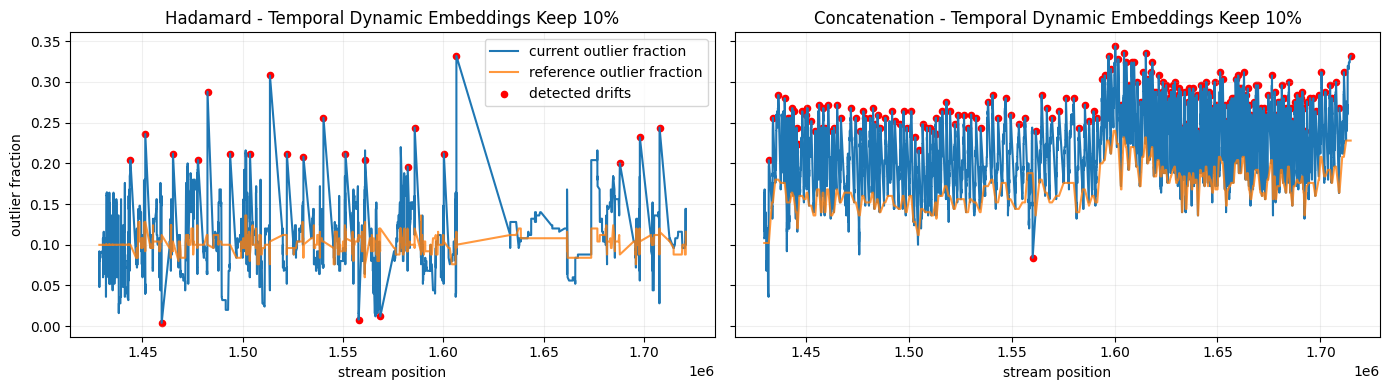

In [28]:
def print_drift_timestamps(label, drifts_df):
    # Print compact drift timestamp summaries.
    if drifts_df.empty:
        print(f'{label}: no drifts detected')
        return
    cols = ['drift_event_id', 'stream_position', 'row_number', 'timestamp', 'current_outlier_fraction']
    print(f'{label}:')
    print(drifts_df[cols].to_string(index=False))


fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, title, result in [
    (axes[0], 'Hadamard - Temporal Dynamic Embeddings Keep 10%', hadamard_result),
    (axes[1], 'Concatenation - Temporal Dynamic Embeddings Keep 10%', concat_result),
]:
    history = result['window_history']
    drifts = result['drifts']
    if history.empty:
        ax.set_title(f'{title} (no history)')
        ax.set_xlabel('stream position')
        ax.grid(alpha=0.2)
        continue
    ax.plot(history['stream_position'], history['current_outlier_fraction'], label='current outlier fraction')
    ax.plot(history['stream_position'], history['reference_outlier_fraction'], label='reference outlier fraction', alpha=0.8)
    if not drifts.empty:
        ax.scatter(drifts['stream_position'], drifts['current_outlier_fraction'], color='red', s=20, label='detected drifts')
    ax.set_title(title)
    ax.set_xlabel('stream position')
    ax.grid(alpha=0.2)

axes[0].set_ylabel('outlier fraction')
axes[0].legend(loc='best')
plt.tight_layout()

print_drift_timestamps('Hadamard', hadamard_result['drifts'])
print_drift_timestamps('Concatenation', concat_result['drifts'])
